# 11. Mobility data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/11_mobility.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/11_mobility.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-11.svg" alt="duckOSM notebook manual, chapter 11: Mobility data" width="100%">

| **You learn** | what mobility data is; how map matching works; `match` for GPS traces; `snap` for sensors; counts for each edge and hour with `aggregate`; your data on the edges with `join`; speeds on the edges with movingpandas; how your data stays after a rebuild with `edge_id_map` |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[analysis,viz]` (the install cell installs them) |
| **Next** | [12. Traffic simulation](12_sim.md): SUMO and MATSim networks, and the results back on the edges |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
# roadstyle (the maps) also comes from its nightly wheel, so the newest roadstyle parts work with no roadstyle release.
import importlib.util, json, os, urllib.request
def nightly_wheel(repo="Khoshkhah/duckOSM", name=".whl"):        # the address of the newest nightly wheel of a repository
    release = json.load(urllib.request.urlopen(f"https://api.github.com/repos/{repo}/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if name in a["name"] and a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[analysis,viz] @ {nightly_wheel()}"
    %pip install -q movingpandas
    %pip install -q --force-reinstall --no-deps "roadstyle @ {nightly_wheel('Khoshkhah/roadstyle', 'manylinux')}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## What mobility data is

**Mobility data** tells you how people and vehicles move on the roads. It comes in three kinds. Each kind needs one
step before you can use it with the network: you must find the edges that it belongs to.

| Data | What it is | The question | The call |
|---|---|---|---|
| GPS traces | a chain of points of one vehicle or person: a phone, a taxi, a bus, a bicycle | which edges did the trip use? | `match` |
| Fixed points | one point with no route: a traffic sensor, a camera, an address, a shop | which edge is the point on? | `snap` |
| Values on the edges | counts, speeds or any number for each edge (often the result of `match` or `snap`) | how many, and when? | `aggregate`, `join` |

The module `duckosm.mobility` has these calls. Each call takes a `ModeView` (`net.driving`), a `Network` with one
mode, or the path of a file with `mode=`. The snap, the map matching and the edge id map run in Rust, in the same
engine as the build.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> Every kind of mobility data ends as rows with an `edge_id`. When your data has the `edge_id`, you can join it to the edges, draw it on a map, compare it with other data, and keep it after the next build.

## How map matching works

A GPS point is not exactly on the road. A phone in a city is often 5 to 10 m off, and more between tall buildings.
The nearest edge of each point is therefore often wrong: near a junction, the nearest edge can be a side street, and
on a two-way road the nearest edge can be the other direction. **Map matching** finds the route that the vehicle
drove: a chain of edges that is near the points *and* is a possible drive from one point to the next.

`match` uses the hidden Markov model of Newson and Krumm (2009), solved with the Viterbi algorithm. leuvenmapmatching,
Valhalla and GraphHopper use the same model.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/mapmatch-flow.svg" alt="The steps of map matching: the GPS points, the candidate edges, the probabilities, the Viterbi algorithm and the match" width="100%">

The table gives each step of the picture, what it does, and the option of `match` that controls it.

| Part | What it does | Option |
|---|---|---|
| Candidates | each edge within `radius_m` of a point is a possible edge for it (a state) | `radius_m`, default 50 m |
| Emission | a point is more probable on a near edge: a normal distribution of the distance | `sigma_m`, the GPS error, default 5 m |
| Transition | a step from one edge to the next is more probable when the route along the roads is as long as the straight line between the two points | `beta_m`, default 10 m |
| U-turn | a turn onto the other direction of the same road costs more | `uturn_m`, default 50 m |
| Viterbi | the algorithm finds the chain of candidates with the highest total probability | |

The route between two points follows the edge directions, so on a two-way road the match selects the edge of the
travel direction. When no candidate of a point can follow the point before it (a gap in the trace), the trace starts
again at that point. The turn restrictions do not apply in the match.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The reference page [duckosm.mobility](../reference/sdk/mobility.md) gives the accuracy of `match` on Monaco for 3 m and 5 m of GPS noise.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The calls use the driving network. `drive` is the view of the driving mode: the calls of
`duckosm.mobility` take it as their first argument.

In [2]:
from duckosm import mobility as mob                                         # the module of this chapter
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
drive = net.driving                                                         # the driving mode
drive                                                                       # the card

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


The driving network of Monaco has 2840 edges and 1768 nodes, 96.2 km of roads.

## Make GPS traces

You need GPS traces to try `match`. This section makes two traces from known routes, so you can compare the match
with the truth. A real GPS file has the same four columns:

| Column | Meaning |
|---|---|
| `trace_id` | the trip that the point belongs to |
| `x` | the longitude, in degrees |
| `y` | the latitude, in degrees |
| `time` | the time of the point: `match` puts the points of each trace in this order |

The function `gps` takes a route of `drive.route` (chapter 7), puts a point every 15 m along it, and moves each point
up to about 4 m off the road at random. The vehicle drives at 8 m/s (about 29 km/h).

In [3]:
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.ops import linemerge

def gps(route, trace_id, seed):                                        # made-up GPS points along a route
    roads = net.driving.edges(crs="utm").set_index("edge_id").loc[route["edges"]]    # the edges of the route, in metres
    line = linemerge(list(roads.geometry))                             # one line
    rng = np.random.default_rng(seed)                                  # noise that does not change
    d = np.arange(0, line.length, 15.0)                                # a point every 15 m
    xy = np.array([line.interpolate(m).coords[0] for m in d]) + rng.normal(0, 4, (len(d), 2))    # 4 m off the road
    p = gpd.GeoSeries(gpd.points_from_xy(xy[:, 0], xy[:, 1]), crs=roads.crs).to_crs(4326)    # back to lon, lat
    return pd.DataFrame({"trace_id": trace_id, "x": p.x, "y": p.y,
                         "time": pd.Timestamp("2026-11-20 08:00") + pd.to_timedelta(d / 8, "s")})    # 8 m/s

A, B = (7.4155, 43.7285), (7.4335, 43.7468)                            # two points in Monaco
there, back = drive.route(A, B), drive.route(B, A)                     # the true routes
traces = pd.concat([gps(there, "there", 1), gps(back, "back", 2)], ignore_index=True)    # the GPS file
print(len(traces), "points;", traces.groupby("trace_id").size().to_dict())    # the points of each trace
traces.head()                                                          # the first points

396 points; {'back': 200, 'there': 196}


,trace_id,x,y,time
0,there,7.415578,43.728611,2026-11-20 08:00:00.000
1,there,7.415434,43.728618,2026-11-20 08:00:01.875
2,there,7.415362,43.728789,2026-11-20 08:00:03.750
3,there,7.415353,43.728919,2026-11-20 08:00:05.625
4,there,7.415527,43.729007,2026-11-20 08:00:07.500


The two traces have 396 points: 196 for "there" and 200 for "back". The points of each trace are 1.875 s apart
(15 m at 8 m/s). The trace "there" drives from the south-west of Monaco to the north-east, and "back" drives the
other way.

## Match the traces: `match`

`mob.match(view, traces)` gives a `Match` with two tables:

| Table | One row for | Columns |
|---|---|---|
| `m.points` | each GPS point | the columns of your points, and `edge_id`, `fraction`, `distance_m`, `snap_x`, `snap_y` |
| `m.edges` | each edge of the route of each trace, in order | `trace_id`, `seq`, `edge_id` |

`m.edges` includes the edges between two points, so the route has no gaps even when the points are far apart. The
column names of your file can differ: give them with `trace=`, `time=`, `x=` and `y=`. `trace=None` matches all the
points as one trace.

In [4]:
m = mob.match(drive, traces)                                          # map matching
for name, true in [("there", there), ("back", back)]:                     # each drive
    got = m.edges[m.edges.trace_id == name].edge_id                       # its matched edges
    print(f"{name}: {got.isin(true['edges']).sum()} of {len(true['edges'])} route edges found, "
          f"{(~got.isin(true['edges'])).sum()} other")                     # compare with the true route

there: 74 of 75 route edges found, 5 other
back: 64 of 64 route edges found, 2 other


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The match finds 74 of the 75 edges of the route "there" and all 64 edges of "back". It adds 5 and 2 other edges. Both drives use the same two-way roads in opposite directions, and the match gives each drive the edges of its own direction. With 4 m of GPS noise, a point near a junction can add the edge before or after the route, or a short road next to it.

### The points

`m.points` has one row for each GPS point, with the edge of the point and the place on the edge.

| Column | Meaning |
|---|---|
| `edge_id` | the edge of the point (missing when no edge is within `radius_m`) |
| `fraction` | the place on the edge: 0 at its start, 1 at its end |
| `distance_m` | the distance from the GPS point to the edge, in metres |
| `snap_x`, `snap_y` | the point on the edge (lon, lat) |

In [5]:
m.points[["trace_id", "time", "edge_id", "fraction", "distance_m"]].head()    # the points on the edges

,trace_id,time,edge_id,fraction,distance_m
0,back,2026-11-20 08:00:00.000,9164240563030343962,1.000000,2.224033
1,back,2026-11-20 08:00:01.875,5478627982403126609,1.000000,8.540619
2,back,2026-11-20 08:00:03.750,5789221358051408561,0.302176,3.399100
3,back,2026-11-20 08:00:05.625,5751627512069328654,0.070886,2.802146
4,back,2026-11-20 08:00:07.500,5751627512069328654,0.603390,2.431693


The first rows are the trace "back": `match` sorts the points by `trace_id`, then by
`time`. Each point is a few metres from its edge, as the noise of the traces. Two points can share one edge, with a
larger `fraction` for the later point.

### The route of each trace

`m.edges` is the route of each trace, edge by edge. `seq` counts the edges of one trace from 0. With
`net.edges(where=...)` you get the names and the lengths of the edges of the route.

In [6]:
route = m.edges[m.edges.trace_id == "there"]                              # the route of one trace
names = net.driving.edges(where=f"edge_id IN ({','.join(map(str, route.edge_id))})").set_index("edge_id")
route = route.join(names[["name", "length_m"]], on="edge_id")             # the name and the length of each edge
print(round(route.length_m.sum()), "m matched;", round(there["length_m"]), "m true")    # the two lengths
route.head(8)

3012 m matched; 2939 m true


,trace_id,seq,edge_id,name,length_m
66,there,0,5871696316595709822,Avenue des Castelans,55.475850
67,there,1,4226571288485271664,Avenue des Castelans,22.594452
68,there,2,3334466758581935624,None,5.880355
69,there,3,8171152212052548045,Avenue Albert II,21.951675
70,there,4,7535252524267336849,Avenue Albert II,22.157495
71,there,5,250554205665761674,Avenue Albert II,5.650921
72,there,6,2390873943090838425,Avenue Albert II,57.861410
73,there,7,724721265073687287,Avenue Albert II,8.340665


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The matched route is 3012 m long, and the true route is 2939 m: the 73 m more are the five other edges. The first edges are on the Avenue des Castelans and the Avenue Albert II, in Fontvieille, in the south-west of Monaco. An edge with `None` as its name has no name in OSM.

### Draw the match

`net.plot(highlight=...)` draws the network and shows the edges of the list in orange. The black dots are the GPS
points.

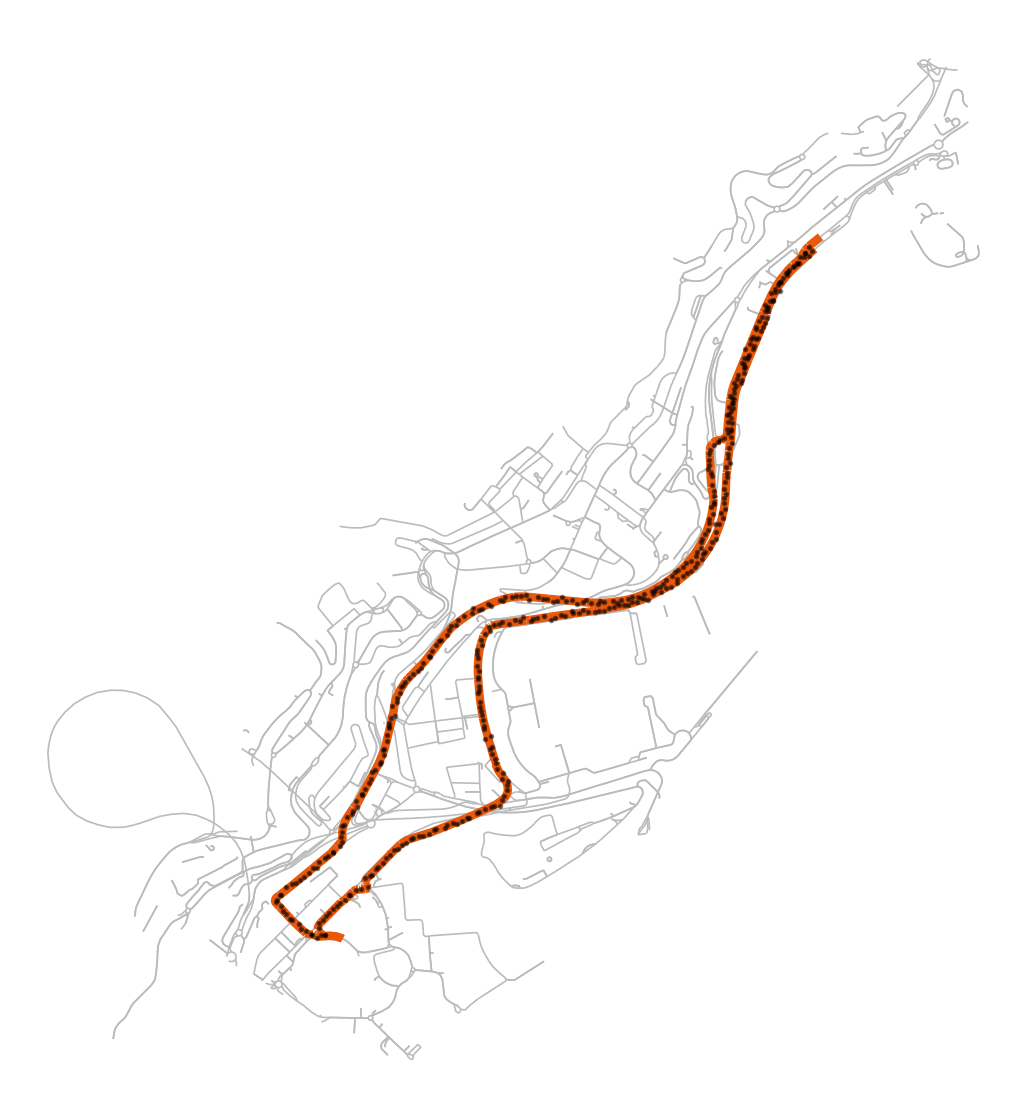

In [7]:
import matplotlib.pyplot as plt

ax = plt.subplots(figsize=(7, 7))[1]                                       # a new picture
net.driving.plot(highlight=m.edges.edge_id, ax=ax)                                 # the matched edges in orange
ax.scatter(traces.x, traces.y, s=1, color="black", alpha=0.5, zorder=3); plt.show()    # the GPS points

The orange route follows the black GPS points from one end to the other. The two
traces drive on the same roads in most places, so one orange line shows both.

### The options of the match

`radius_m` sets the candidates of a point. A smaller radius is faster, but a point that is further from every edge
gets no edge. This cell matches the same traces with `radius_m=5`.

In [8]:
tight = mob.match(drive, traces, radius_m=5)                              # only the edges within 5 m
print(tight.points.edge_id.isna().sum(), "of", len(tight.points), "points without an edge")
print(len(tight.edges), "route edges, against", len(m.edges), "with radius_m=50")

45 of 396 points without an edge
208 route edges, against 145 with radius_m=50


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> With `radius_m=5`, 45 of the 396 points have no edge. The route has 208 edges, against 145 with the default radius. The extra edges are detours: when the correct edge of a point is not a candidate, the match must use a different edge, and some edges come two times. Keep `radius_m` much larger than the GPS error.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Set `sigma_m` to the GPS error of your data. A phone in a car is about 5 m (the default). For data with large errors, increase `sigma_m` and `radius_m` together. For points that are far apart in time (one point each minute), increase `beta_m`, because the route between two points is then much longer than the straight line.

### The second method: GPS-DTW

`method="dtw"` matches with [GPS-DTW](https://khoshkhah.github.io/gps-dtw/), dynamic time warping in Rust. It
interpolates the trace each second and aligns it with points along the roads, in windows of 60 s. The roads of a
window come from a forward and a backward Dijkstra search, with no detour longer than 1.2 times the trace. It needs
the `time` column. `sigma_m`, `beta_m` and `uturn_m` do not apply.

```python
d = mob.match(drive, traces, method="dtw")      # GPS-DTW in place of the HMM
```

On 600 Monaco traces, GPS-DTW is faster at each GPS interval and gives far fewer wrong edges with dense GPS (one point
each 1 to 5 s). The HMM (the default) finds a little more of the route with sparse GPS (15 to 30 s). The numbers:
[duckosm.mobility](https://khoshkhah.github.io/duckOSM/reference/sdk/mobility/).

## Snap fixed points: `snap`

A sensor, an address or a shop is one point with no route. `mob.snap(view, points)` gives the nearest edge of each
point, one point at a time. It adds the same columns as `m.points`. Use `snap` only for points that do not belong to
a trace: for GPS traces, `match` is more correct.

`radius_m` is the largest distance. A point with no edge within it gets no `edge_id`.

In [9]:
sensors = pd.DataFrame({"sensor": ["s1", "s2", "s3"], "x": [7.4206, 7.4262, 7.4301], "y": [43.7316, 43.7397, 43.7427]})
snapped = mob.snap(drive, sensors, radius_m=30)                            # edge_id, fraction, distance_m, snap_x, snap_y
snapped

,sensor,x,y,edge_id,fraction,distance_m,snap_x,snap_y
0,s1,7.4206,43.7316,3913596625020233819,0.918641,6.247255,7.420571,43.731652
1,s2,7.4262,43.7397,1681206748141307799,0.517687,14.168264,7.426373,43.739722
2,s3,7.4301,43.7427,1155660829073038487,0.754625,10.588955,7.430146,43.742789


Each sensor gets one edge. The sensors are 6 to 14 m from their edges. Sensor s1 is
near the end of its edge (`fraction` 0.92), and s2 is near the middle (0.52). `snap_x` and `snap_y` are the points
on the edges: draw them to check the snap.

### Other kinds of points

`points` can be a DataFrame with lon and lat columns (`x=` and `y=` give other names), a GeoDataFrame in any CRS, or
a list of `(lon, lat)`. Here it is a list.

In [10]:
mob.snap(drive, [(7.4246, 43.7384), (7.4100, 43.7300)], radius_m=30)    # a list of (lon, lat)

,x,y,edge_id,fraction,distance_m,snap_x,snap_y
0,7.4246,43.7384,7100204783222915174,0.950615,13.096969,7.424532,43.738293
1,7.4100,43.7300,388717650819614537,0.279334,0.065672,7.410001,43.730000


A list gives a DataFrame with the columns `x` and `y`, and the columns of the snap.
The second point is 0.07 m from its edge: it is almost on the road.

## Count on each edge: `aggregate`

`mob.aggregate(view, matched)` counts the points on each edge in each time bin. `matched` is `m.points` or the result
of `snap`.

| Argument | Default | What it does |
|---|---|---|
| `time` | `"hour"` | the bin: `"hour"`, `"15min"`, `"day"` or any pandas frequency, or `None` for no time bins |
| `time_column` | `"time"` | the column of the time |
| `value` | none | a column of numbers: adds `<value>_mean`, its mean in each bin |
| `by` | `"edge_id"` | the column to group by |

The result has the columns `edge_id`, `time` (the start of the bin), `count`, and `<value>_mean`.

In [11]:
counts = mob.aggregate(drive, m.points, time="hour")                     # edge_id, time, count
print(len(counts), "rows;", counts["count"].sum(), "points")              # every point is in one row
counts.head()

119 rows; 396 points


,edge_id,time,count
0,201269546770482535,2026-11-20 08:00:00,6
1,240162084728701473,2026-11-20 08:00:00,7
2,250554205665761674,2026-11-20 08:00:00,1
3,545218161373926197,2026-11-20 08:00:00,8
4,588819565861269928,2026-11-20 08:00:00,6


The 396 points are on 119 edges, so the table has 119 rows. All the points are between 08:00 and 09:00, so each edge has one row
for the hour 08:00.

### Smaller time bins and a mean value

With `time="5min"`, each edge gets one row for each 5 minutes in which it has points. With `value="distance_m"`, each row also has the
mean distance of its points from the edge: a measure of the GPS error on that edge.

In [12]:
q = mob.aggregate(drive, m.points, time="5min", value="distance_m")     # bins of 5 minutes, and the mean distance
print(sorted(q.time.dt.strftime("%H:%M").unique()))                       # the bins
q.sort_values("distance_m_mean", ascending=False).head(3)                  # the edges with the largest GPS error

['08:00', '08:05']


,edge_id,time,count,distance_m_mean
79,5649374032014463393,2026-11-20 08:00:00,1,29.777660
76,5478627982403126609,2026-11-20 08:00:00,1,8.540619
80,5649374032014463393,2026-11-20 08:05:00,1,6.954302


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Each drive takes about 6 minutes, so the points are in two bins, 08:00 and 08:05. The largest mean distance is 29.8 m, for one point in the bin 08:00. The same edge has one more point in the bin 08:05, at 7.0 m: the bins split the points of one edge by their time. One point far from its edge is often a point near a junction, where the next edge is near too.

## Put your data on the edges: `join`

`mob.join(view, data)` gives a GeoDataFrame of the edges with the columns of `data`. `data` is a DataFrame with an
`edge_id` column, or a Series whose index is the `edge_id`. `how="inner"` (the default) keeps only the edges with data,
and `how="left"` keeps all the edges, with no value where there is no data.

In [13]:
by_edge = counts.groupby("edge_id")["count"].sum()                         # the points on each edge
on_map = mob.join(drive, by_edge)                                          # the edges with data
print(len(on_map), "edges with data;", len(mob.join(drive, by_edge, how="left")), "edges in all")
on_map[["edge_id", "name", "count"]].nlargest(3, "count")                 # the three edges with the most points

119 edges with data; 2840 edges in all


,edge_id,name,count
43,3487789174266503140,Boulevard du Larvotto,21
112,8691687783733863412,Tunnel Dorsale,17
49,3913596625020233819,Tunnel Rocher Palais,14


119 edges have data, of the 2840 edges of the network. The Boulevard du Larvotto has the
most points (21), then the Tunnel Dorsale (17) and the Tunnel Rocher Palais (14). A long edge gets more points, because the traces put one point every 15 m.

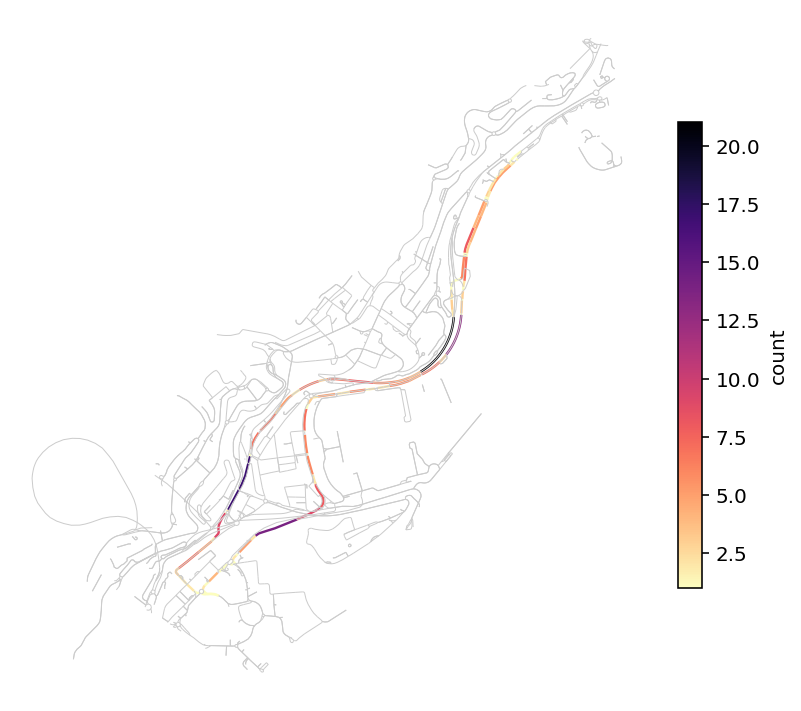

In [14]:
net.driving.plot(color_by=by_edge, cmap="magma_r")                                 # the map, colored by the count

The colors show the number of points on each edge. The long edges of the route
(the boulevard along the sea and the tunnels) are the darkest.

## Trajectories with movingpandas

[movingpandas](https://movingpandas.org) is a Python library for tracks: it turns GPS points into trajectories, and
it measures their length, duration, speed and direction. duckOSM puts the points on the edges. Together they answer
"how fast do vehicles drive on each street":

| Tool | What it gives |
|---|---|
| movingpandas | the speed at each GPS point, from the distance and the time to the point before |
| duckOSM | the edge of each point (`match`), and the mean of a value on each edge (`aggregate`) |

The steps:

1. Make one movingpandas trajectory for each trace, from the same table `traces`.
2. Add the speed of each point, in km/h.
3. Put the speeds on the matched points of `m.points` (the same trace and time), and take the mean speed of each
   edge with `aggregate`.
4. Draw the edges in the color of their speed.

In [15]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")              # movingpandas warns about an optional part that this chapter does not use
    import movingpandas as mpd

tc = mpd.TrajectoryCollection(traces, traj_id_col="trace_id", t="time", x="x", y="y", crs=4326)    # 1. one for each trace
tc.add_speed(units=("km", "h"))                                                 # 2. the speed of each point, km/h
pd.DataFrame({"length_m": [round(t.get_length()) for t in tc],                  # the length of each trajectory
              "route_m": [round({"there": there, "back": back}[t.id].length_m) for t in tc],    # the true route
              "minutes": [round(t.get_duration().total_seconds() / 60, 1) for t in tc],
              "mean_kmh": [round(t.df.speed.mean(), 1) for t in tc]}, index=[t.id for t in tc])

,length_m,route_m,minutes,mean_kmh
back,3179,3002,6.2,30.7
there,3151,2939,6.1,31.0


Each trajectory takes about 6 minutes. Its length (3,151 m and 3,179 m) is about 200 m more than the true route
(2,939 m and 3,002 m): the GPS noise makes the line zigzag, so it is longer than the road. So the mean speed is
31 km/h, not the true 28.8 km/h (8 m/s) of the made-up traces.

In [16]:
speeds = tc.to_point_gdf().reset_index()[["trace_id", "time", "speed"]]        # the speed of each GPS point
points = m.points.merge(speeds, on=["trace_id", "time"])                       # 3. each matched point with its speed
by_speed = mob.aggregate(drive, points, time=None, value="speed")              # the mean speed on each edge
by_speed.speed_mean.describe()[["count", "50%", "min", "max"]].round(1)        # the speeds of the edges, km/h

count    119.0
50%       31.0
min        3.9
max       56.2
Name: speed_mean, dtype: float64

119 edges get a mean speed, and the middle edge has 31 km/h. A few edges with only one or two points show
4 km/h or 56 km/h: with so few points, the GPS noise decides the speed.

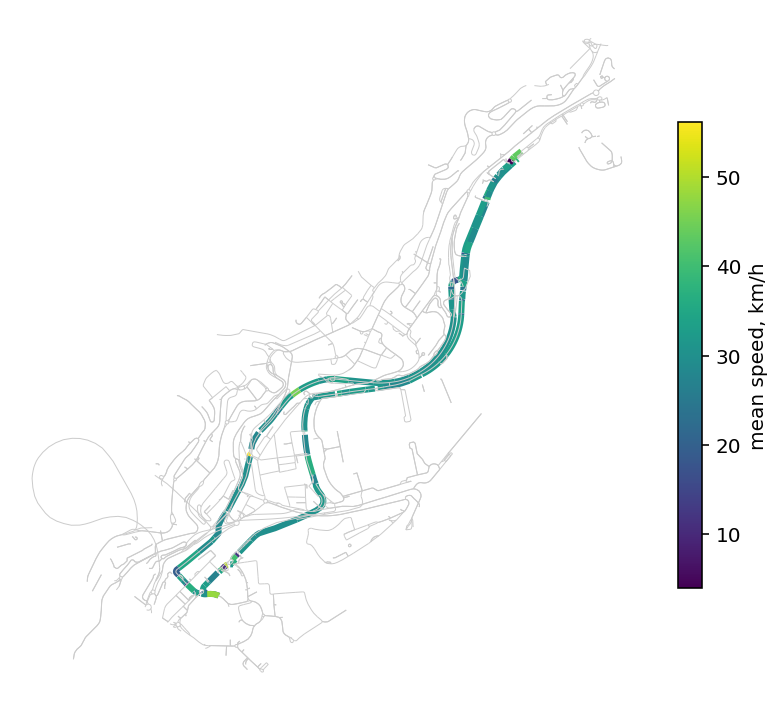

In [17]:
speed = by_speed.set_index("edge_id").speed_mean.rename("mean speed, km/h")    # edge_id -> speed
net.driving.plot(color_by=speed, cmap="viridis", linewidth=3)                   # 4. the edges by speed, thick lines

The colored line is the route of the two traces. Most of it is blue-green: about 30 km/h. The dark purple and
the light green pieces are short edges with few points, near junctions. `linewidth=3` draws the roads with a value thick, because
only 119 of the 2,840 edges have one.

## Keep your data after a rebuild: `edge_id_map`

The `edge_id` of an edge stays the same in a new build when its OSM way and its two ends do not change. An OSM update
or a new fix can split or join edges, and these edges get new ids. Your counts are on the old ids.
`mob.edge_id_map(old, new)` puts the old ids on the new edges:

| Old edge | Rows of `edge_id_map` |
|---|---|
| its `edge_id` is in the new build | one row to itself, `share` 1 |
| split or joined | one row for each new edge of the same OSM way that lies on it in the same direction (within `tol_m`, default 2 m), with the `share` of its length |
| removed | no row |

Here a fix removes the dead-end street 778494662 (chapter 5 tells more about fixes). Its T junction goes, so the road
that it met becomes one edge in each direction, with a new id.

In [18]:
open("fix.yaml", "w").write("overrides:\n  - osm_id: 778494662\n    remove: true\n")    # the fix: remove the street
new = duckosm.network(osm_id=2220322, modes=["driving"], fixes="fix.yaml", name="monaco_fixed")    # build again with it
ids = mob.edge_id_map(drive, new.driving)                                # old edge_id -> new edge_id, share
print(len(ids), "rows;", (ids.old_edge_id == ids.new_edge_id).sum(), "edges keep their id")
ids[ids.old_edge_id != ids.new_edge_id]                                  # the edges that changed

cut with the fixes: 34461 nodes, 5684 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco_fixed-20261121-170531-8d32/monaco_fixed.duckdb

2838 rows; 2834 edges keep their id


,old_edge_id,new_edge_id,share
349,1135803928808390220,4352433216998100260,1.0
1129,3640886082708460898,4352433216998100260,1.0
1411,4481486712828221748,105595499196454544,1.0
1414,4495873536865053102,105595499196454544,1.0


The old network has 2840 edges, and the map has 2838 rows. 2834 edges keep their id. The
four changed rows are two old edges in each direction: each pair becomes one new edge. The two edges of the removed
street have no row.

### Move the counts to the new edges

Join your data on `old_edge_id`, and multiply each value by `share`. A count is then divided between the new edges
when an old edge is split, and added when old edges are joined.

In [19]:
moved = counts.merge(ids, left_on="edge_id", right_on="old_edge_id")     # the counts on the new edges
moved["count"] = moved["count"] * moved.share                            # a split edge shares its count
print(counts["count"].sum(), "points before,", round(moved["count"].sum(), 1), "after")    # no count is lost

396 points before, 396.0 after


The 396 points of the old edges are all on the new edges. No point was on the removed
street.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A mean (a speed, a distance) must not be multiplied by `share`. Multiply only values that you can add, for example counts and lengths. For a mean, give each new edge the value of its old edge.

## Try it yourself

**1.** Match only the trace "back" as one trace, with `trace=None`, and count its route edges.

<details><summary>Show the answer</summary>

```python
one = mob.match(drive, traces[traces.trace_id == "back"], trace=None)   # all the points are one trace
len(one.edges)
```
</details>

**2.** Add about 6 m more GPS noise to the trace "there", match it with `sigma_m=10`, and compare the found edges.

<details><summary>Show the answer</summary>

```python
noisy = pd.concat([gps(there, "there", 1)], ignore_index=True)
noisy[["x", "y"]] += np.random.default_rng(3).normal(0, 0.00008, (len(noisy), 2))   # about 6 m more in each axis
mn = mob.match(drive, noisy, sigma_m=10)                                   # a larger GPS error
mn.edges.edge_id.isin(there["edges"]).sum(), len(there["edges"])
```
</details>

**3.** Snap the sensors, then use `join` with `how="left"` to find how many edges have no sensor.

<details><summary>Show the answer</summary>

```python
s = mob.snap(drive, sensors, radius_m=30)
j = mob.join(drive, s[["edge_id", "sensor"]], how="left")
j.sensor.isna().sum()
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| GPS trace | the points of one trip, in the order of their time |
| map matching | finding the edges that a GPS trace drove |
| candidate | an edge near a GPS point that can be its edge |
| hidden Markov model | a model of states that you cannot see (the edges) and points that you see (the GPS points) |
| Viterbi algorithm | the algorithm that finds the most probable chain of states |
| snap | putting one point on its nearest edge |
| fraction | the place of a point on its edge: 0 at the start, 1 at the end |
| time bin | a part of the time, for example one hour, in which `aggregate` counts |
| share | the part of an old edge that lies on a new edge, in `edge_id_map` |

## Summary

| Call | Does |
|---|---|
| `mob.match(view, traces, ...)` | map matching: `Match(points, edges)`, the edge of each point and the route of each trace |
| `mob.Match` | the result of `match`: `points` and `edges` |
| `mob.snap(view, points, radius_m=...)` | the nearest edge of each point, for sensors and addresses |
| `mob.aggregate(view, matched, time=..., value=...)` | counts (and means) for each edge and time bin |
| `mob.join(view, data, how=...)` | your data on the edges, as a GeoDataFrame |
| `mob.edge_id_map(old, new, tol_m=...)` | the old edge ids on the edges of a new build, with the share |

The reference: [duckosm.mobility](../reference/sdk/mobility.md). **Next:** [12. Traffic simulation](12_sim.md), SUMO and MATSim networks, and the results back on the edges.